In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
# First step to Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

# Set display options for better readability
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("DONE")

DONE


DATA OVERVIEW

In [ ]:
# Load the automobile dataset from Google Drive
file_path = '/content/drive/MyDrive/Great Learning/Case Study/austo_automobile .csv'
data = pd.read_csv(file_path)

df= data.copy()
#to avoid any chnages to original data

print("Dataset loaded successfully!")
print(f"Dataset shape: {df.shape}")
print(f"Total records: {df.shape[0]}")
print(f"Total variables: {df.shape[1]}")

NameError: name 'pd' is not defined

 Check Data Structure

In [ ]:
# to analyse and see how is the data and later compare with the types : Displaying first 5 rows
print("First 5 rows of the dataset:")
print(df.head())


First 5 rows of the dataset:
   Age  Gender Profession Marital_status      Education  No_of_Dependents  \
0   53    Male   Business        Married  Post Graduate                 4   
1   53   Femal   Salaried        Married  Post Graduate                 4   
2   53  Female   Salaried        Married  Post Graduate                 3   
3   53  Female   Salaried        Married       Graduate                 2   
4   53    Male   Salaried        Married  Post Graduate                 3   

  Personal_loan House_loan Partner_working  Salary  Partner_salary  \
0            No         No             Yes   99300         70700.0   
1           Yes         No             Yes   95500         70300.0   
2            No         No             Yes   97300         60700.0   
3           Yes         No             Yes   72500         70300.0   
4            No         No             Yes   79700         60200.0   

   Total_salary  Price Make  
0        170000  61000  SUV  
1        165800  61000  SUV

Dataset Information

In [ ]:
# Check data types of all columns
print("\nColumn names and data types:")
print(df.dtypes)

print("\nDataset info:")
print(df.info())


Column names and data types:
Age                   int64
Gender               object
Profession           object
Marital_status       object
Education            object
No_of_Dependents      int64
Personal_loan        object
House_loan           object
Partner_working      object
Salary                int64
Partner_salary      float64
Total_salary          int64
Price                 int64
Make                 object
dtype: object

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1581 entries, 0 to 1580
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               1581 non-null   int64  
 1   Gender            1528 non-null   object 
 2   Profession        1581 non-null   object 
 3   Marital_status    1581 non-null   object 
 4   Education         1581 non-null   object 
 5   No_of_Dependents  1581 non-null   int64  
 6   Personal_loan     1581 non-null   object 
 7   House_loan    

* In Gender and Partner salary, we see that the count is less.

Check for Missing Values

*  Missing values in each column


In [ ]:
print(df.isnull().sum())

Age                   0
Gender               53
Profession            0
Marital_status        0
Education             0
No_of_Dependents      0
Personal_loan         0
House_loan            0
Partner_working       0
Salary                0
Partner_salary      106
Total_salary          0
Price                 0
Make                  0
dtype: int64


* Total missing values in dataset

In [ ]:
print(df.isnull().sum().sum())

159


* Calculate percentage of missing values

In [ ]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage)

Age                 0.000000
Gender              3.352309
Profession          0.000000
Marital_status      0.000000
Education           0.000000
No_of_Dependents    0.000000
Personal_loan       0.000000
House_loan          0.000000
Partner_working     0.000000
Salary              0.000000
Partner_salary      6.704617
Total_salary        0.000000
Price               0.000000
Make                0.000000
dtype: float64


Statistical Summary - Numerical Variables

In [ ]:
print(df.describe().T)

                   count          mean           std      min      25%  \
Age               1581.0     31.922201      8.425978     22.0     25.0   
No_of_Dependents  1581.0      2.457938      0.943483      0.0      2.0   
Salary            1581.0  60392.220114  14674.825044  30000.0  51900.0   
Partner_salary    1475.0  20225.559322  19573.149277      0.0      0.0   
Total_salary      1581.0  79625.996205  25545.857768  30000.0  60500.0   
Price             1581.0  35597.722960  13633.636545  18000.0  25000.0   

                      50%      75%       max  
Age                  29.0     38.0      54.0  
No_of_Dependents      2.0      3.0       4.0  
Salary            59500.0  71800.0   99300.0  
Partner_salary    25600.0  38300.0   80500.0  
Total_salary      78000.0  95900.0  171000.0  
Price             31000.0  47000.0   70000.0  


* The age variable is more left skewed.

 * Additional Statistics
 *Calculate additional measures for numerical columns*

* This gives idea and also a sense of outliers (if incase any)

In [ ]:
numerical_cols = df.select_dtypes(include=[np.number]).columns

for col in numerical_cols:
    print(f"\n{col}:")
    print(f"  Mean: {df[col].mean():.2f}")
    print(f"  Median: {df[col].median():.2f}")
    print(f"  Standard Deviation: {df[col].std():.2f}")
    print(f"  Minimum: {df[col].min():.2f}")
    print(f"  Maximum: {df[col].max():.2f}")
    print(f"  Range: {df[col].max() - df[col].min():.2f}")


Age:
  Mean: 31.92
  Median: 29.00
  Standard Deviation: 8.43
  Minimum: 22.00
  Maximum: 54.00
  Range: 32.00

No_of_Dependents:
  Mean: 2.46
  Median: 2.00
  Standard Deviation: 0.94
  Minimum: 0.00
  Maximum: 4.00
  Range: 4.00

Salary:
  Mean: 60392.22
  Median: 59500.00
  Standard Deviation: 14674.83
  Minimum: 30000.00
  Maximum: 99300.00
  Range: 69300.00

Partner_salary:
  Mean: 20225.56
  Median: 25600.00
  Standard Deviation: 19573.15
  Minimum: 0.00
  Maximum: 80500.00
  Range: 80500.00

Total_salary:
  Mean: 79626.00
  Median: 78000.00
  Standard Deviation: 25545.86
  Minimum: 30000.00
  Maximum: 171000.00
  Range: 141000.00

Price:
  Mean: 35597.72
  Median: 31000.00
  Standard Deviation: 13633.64
  Minimum: 18000.00
  Maximum: 70000.00
  Range: 52000.00


Check for Data Irregularities (Data Sanity Checks)

* Unique values in categorical columns

In [ ]:
categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())
    print(f"Total unique values: {df[col].nunique()}")


Gender:
Gender
Male      1199
Female     327
Femal        1
Femle        1
Name: count, dtype: int64
Total unique values: 4

Profession:
Profession
Salaried    896
Business    685
Name: count, dtype: int64
Total unique values: 2

Marital_status:
Marital_status
Married    1443
Single      138
Name: count, dtype: int64
Total unique values: 2

Education:
Education
Post Graduate    985
Graduate         596
Name: count, dtype: int64
Total unique values: 2

Personal_loan:
Personal_loan
Yes    792
No     789
Name: count, dtype: int64
Total unique values: 2

House_loan:
House_loan
No     1054
Yes     527
Name: count, dtype: int64
Total unique values: 2

Partner_working:
Partner_working
Yes    868
No     713
Name: count, dtype: int64
Total unique values: 2

Make:
Make
Sedan        702
Hatchback    582
SUV          297
Name: count, dtype: int64
Total unique values: 3


* I noticed "Gender:
Gender
Male      1199
Female     327
Femal        1
Femle        1"

Data Cleaning


* Before cleaning

In [ ]:
print(df['Gender'].value_counts())

Gender
Male      1199
Female     327
Femal        1
Femle        1
Name: count, dtype: int64


In [ ]:
mode_gender = df['Gender'].mode()[0]
df['Gender'] = df['Gender'].fillna(mode_gender)
df['Gender'] = df['Gender'].replace(['Femal', 'Femle'], 'Female')
print(df.isnull().sum())

Age                   0
Gender                0
Profession            0
Marital_status        0
Education             0
No_of_Dependents      0
Personal_loan         0
House_loan            0
Partner_working       0
Salary                0
Partner_salary      106
Total_salary          0
Price                 0
Make                  0
dtype: int64


* After cleaning

In [ ]:
print(df['Gender'].value_counts())

Gender
Male      1252
Female     329
Name: count, dtype: int64


* Data cleaned. I ensured consistency in categorical data

Summary of Data Overview

* Dataset Dimensions

In [ ]:

print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")


Rows: 1581
Columns: 14


* Variable Types

In [ ]:
print(f"Numerical variables: {len(df.select_dtypes(include=[np.number]).columns)}")
print(f"Categorical variables: {len(df.select_dtypes(include='object').columns)}")

Numerical variables: 6
Categorical variables: 8


* Data Quality

In [ ]:
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")

Missing values: 106
Duplicate rows: 0


In [ ]:
df['Partner_salary'].unique()

array([70700., 70300., 60700., 60200., 60500., 50800., 40400.,     0.,
       70600., 60600., 60300., 45500., 40200., 40700.,   600.,   700.,
       27800., 70000., 40100., 40900., 27000.,    nan, 40500., 50400.,
       80400., 60900., 60100., 70200., 30000., 40300., 40800., 70800.,
         900., 45000., 40600., 50700., 80500., 27700., 35800., 26600.,
       60000., 27900., 60800., 40000., 70100., 38100., 38200., 30200.,
       38500., 50900., 35100., 38700., 38300., 38900., 23200., 24700.,
       30800., 28100., 38400., 38000., 23100., 30100., 25700., 70400.,
         200., 30900., 26100., 45700.,   400., 28200., 70900., 38800.,
       45200., 26800., 60400., 30300., 25800.,   800., 38600., 24500.,
       30700., 28500., 24900., 70500., 35900., 30500., 28900., 27200.,
       45900., 25300., 35600., 25000., 25200., 26300., 35700., 23800.,
       32700., 30600., 45600., 28000., 32600., 28600., 25100., 26700.,
       24200., 25900., 22100., 25400., 28400., 28300., 25500., 24000.,
      

In [ ]:
len(df['Partner_salary'].unique())

150

In [ ]:
df['Partner_salary'].value_counts(normalize=True, dropna = False)

,proportion
Partner_salary,
0.0,0.394054
NaN,0.067046
40500.0,0.018343
40200.0,0.017078
40000.0,0.015813
...,...
300.0,0.000633
22300.0,0.000633
500.0,0.000633


In [ ]:
median_salary = df['Partner_salary'].median()
df['Partner_salary'] = df['Partner_salary'].fillna(median_salary)

print(df.isnull().sum())

Age                 0
Gender              0
Profession          0
Marital_status      0
Education           0
No_of_Dependents    0
Personal_loan       0
House_loan          0
Partner_working     0
Salary              0
Partner_salary      0
Total_salary        0
Price               0
Make                0
dtype: int64


* Key Variables

In [ ]:
print("Age: Range from", df['Age'].min(), "to", df['Age'].max(), "years")
print("Price: Range from ₹", df['Price'].min(), "to ₹", df['Price'].max())
print("Vehicle Types:", df['Make'].unique())

Age: Range from 22 to 54 years
Price: Range from ₹ 18000 to ₹ 70000
Vehicle Types: ['SUV' 'Sedan' 'Hatchback']


In [ ]:
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")

Missing values: 0
Duplicate rows: 0


In [ ]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage)

Age                 0.0
Gender              0.0
Profession          0.0
Marital_status      0.0
Education           0.0
No_of_Dependents    0.0
Personal_loan       0.0
House_loan          0.0
Partner_working     0.0
Salary              0.0
Partner_salary      0.0
Total_salary        0.0
Price               0.0
Make                0.0
dtype: float64


In [ ]:
print(df['Gender'].value_counts())

Gender
Male      1252
Female     329
Name: count, dtype: int64


 **UNIVARIATE ANALYSIS**

* Distribution of Numerical Variables - Histograms



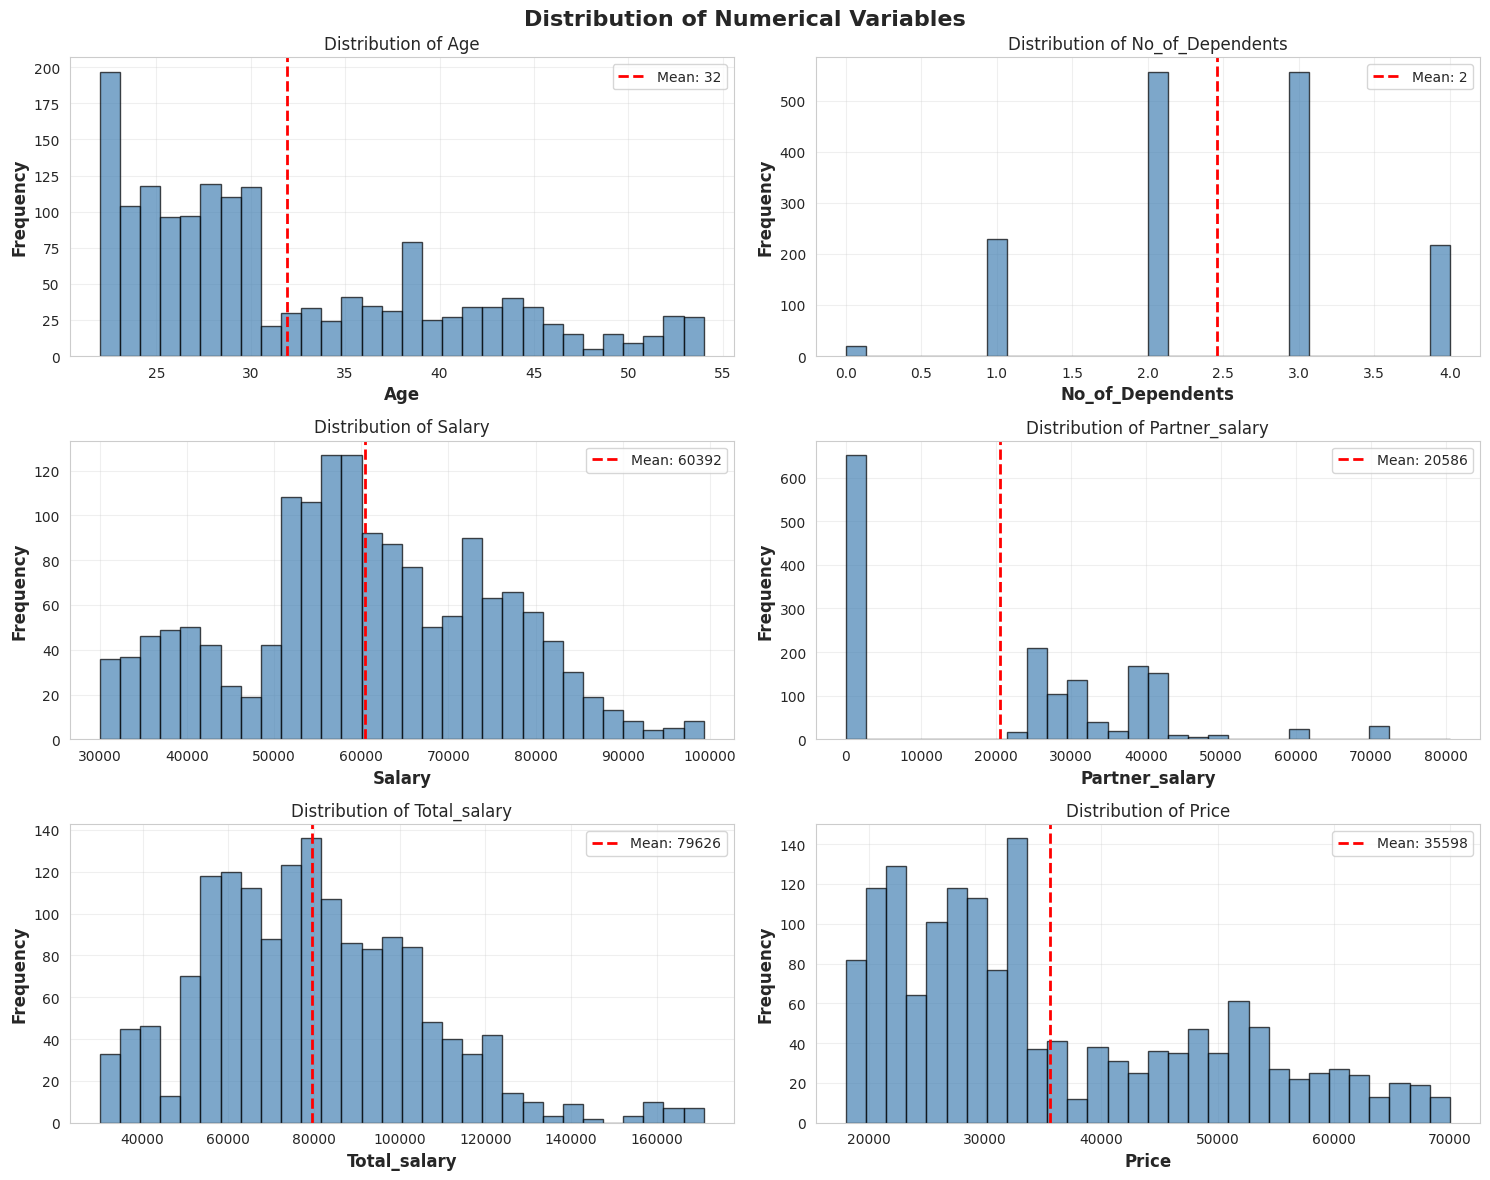

Histograms created successfully!


In [ ]:
# Create histograms for all numerical variables
numerical_cols = ['Age', 'No_of_Dependents', 'Salary', 'Partner_salary',
                  'Total_salary', 'Price']

# Create subplots
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
fig.suptitle('Distribution of Numerical Variables', fontsize=16, fontweight='bold')

# Flatten axes for easier iteration
axes = axes.flatten()

# Plot histogram for each numerical variable
for idx, col in enumerate(numerical_cols):
    axes[idx].hist(df[col], bins=30, color='steelblue', edgecolor='black', alpha=0.7)
    axes[idx].set_xlabel(col, fontsize=12, fontweight='bold')
    axes[idx].set_ylabel('Frequency', fontsize=12, fontweight='bold')
    axes[idx].set_title(f'Distribution of {col}', fontsize=12)
    axes[idx].grid(True, alpha=0.3)

    # Add mean line
    axes[idx].axvline(df[col].mean(), color='red', linestyle='--',
                      linewidth=2, label=f'Mean: {df[col].mean():.0f}')
    axes[idx].legend()

plt.tight_layout()
plt.show()

print("Histograms created successfully!")

Outlier Detection - Boxplots

**Outliers**

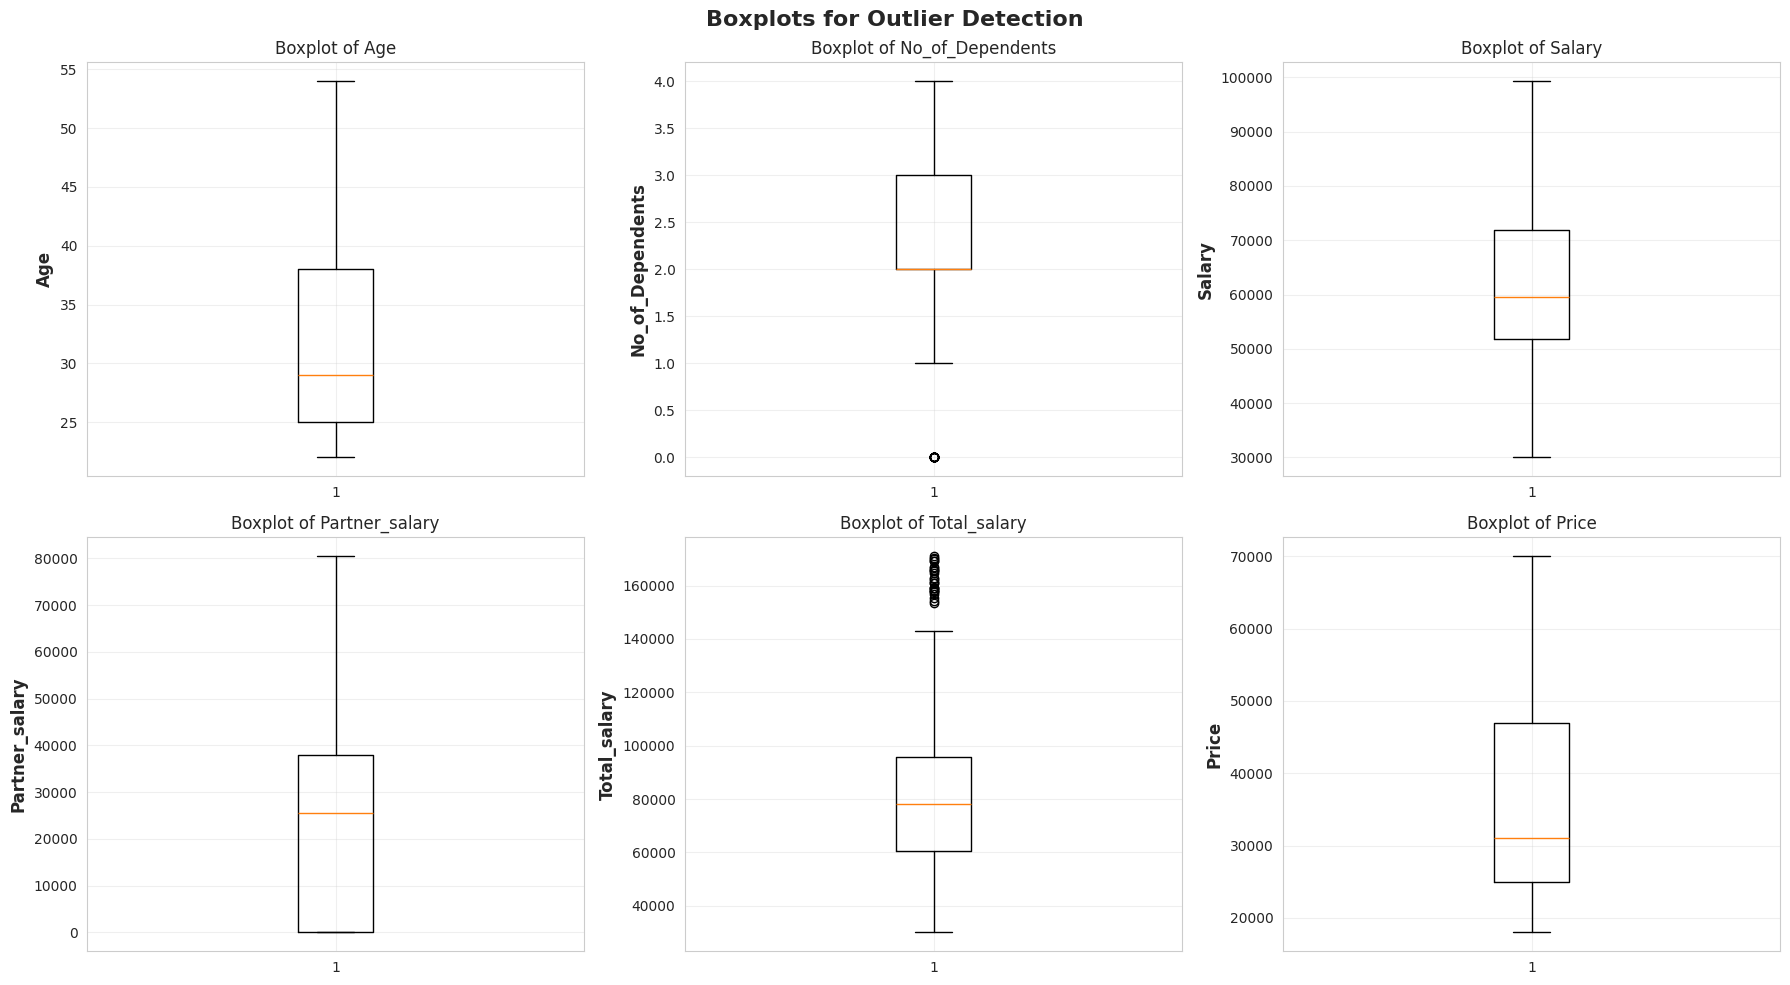

Boxplots created successfully!


In [ ]:
# Create boxplots for numerical variables
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Boxplots for Outlier Detection', fontsize=16, fontweight='bold')

axes = axes.flatten()

for idx, col in enumerate(numerical_cols):
    axes[idx].boxplot(df[col], vert=True)
    axes[idx].set_ylabel(col, fontsize=12, fontweight='bold')
    axes[idx].set_title(f'Boxplot of {col}', fontsize=12)
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Boxplots created successfully!")

 Outlier Analysis using IQR Method

In [ ]:
for col in numerical_cols:
    # Calculate Q1, Q3, and IQR
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    # Calculate bounds
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Find outliers
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print(f"\n{col}:")
    print(f"  Q1 (25th percentile): {Q1:.2f}")
    print(f"  Q3 (75th percentile): {Q3:.2f}")
    print(f"  IQR: {IQR:.2f}")
    print(f"  Lower Bound: {lower_bound:.2f}")
    print(f"  Upper Bound: {upper_bound:.2f}")
    print(f"  Number of outliers: {len(outliers)} ({len(outliers)/len(df)*100:.2f}%)")


Age:
  Q1 (25th percentile): 25.00
  Q3 (75th percentile): 38.00
  IQR: 13.00
  Lower Bound: 5.50
  Upper Bound: 57.50
  Number of outliers: 0 (0.00%)

No_of_Dependents:
  Q1 (25th percentile): 2.00
  Q3 (75th percentile): 3.00
  IQR: 1.00
  Lower Bound: 0.50
  Upper Bound: 4.50
  Number of outliers: 20 (1.27%)

Salary:
  Q1 (25th percentile): 51900.00
  Q3 (75th percentile): 71800.00
  IQR: 19900.00
  Lower Bound: 22050.00
  Upper Bound: 101650.00
  Number of outliers: 0 (0.00%)

Partner_salary:
  Q1 (25th percentile): 0.00
  Q3 (75th percentile): 38000.00
  IQR: 38000.00
  Lower Bound: -57000.00
  Upper Bound: 95000.00
  Number of outliers: 0 (0.00%)

Total_salary:
  Q1 (25th percentile): 60500.00
  Q3 (75th percentile): 95900.00
  IQR: 35400.00
  Lower Bound: 7400.00
  Upper Bound: 149000.00
  Number of outliers: 27 (1.71%)

Price:
  Q1 (25th percentile): 25000.00
  Q3 (75th percentile): 47000.00
  IQR: 22000.00
  Lower Bound: -8000.00
  Upper Bound: 80000.00
  Number of outliers: 

Distribution of Categorical Variables - Bar Graphs

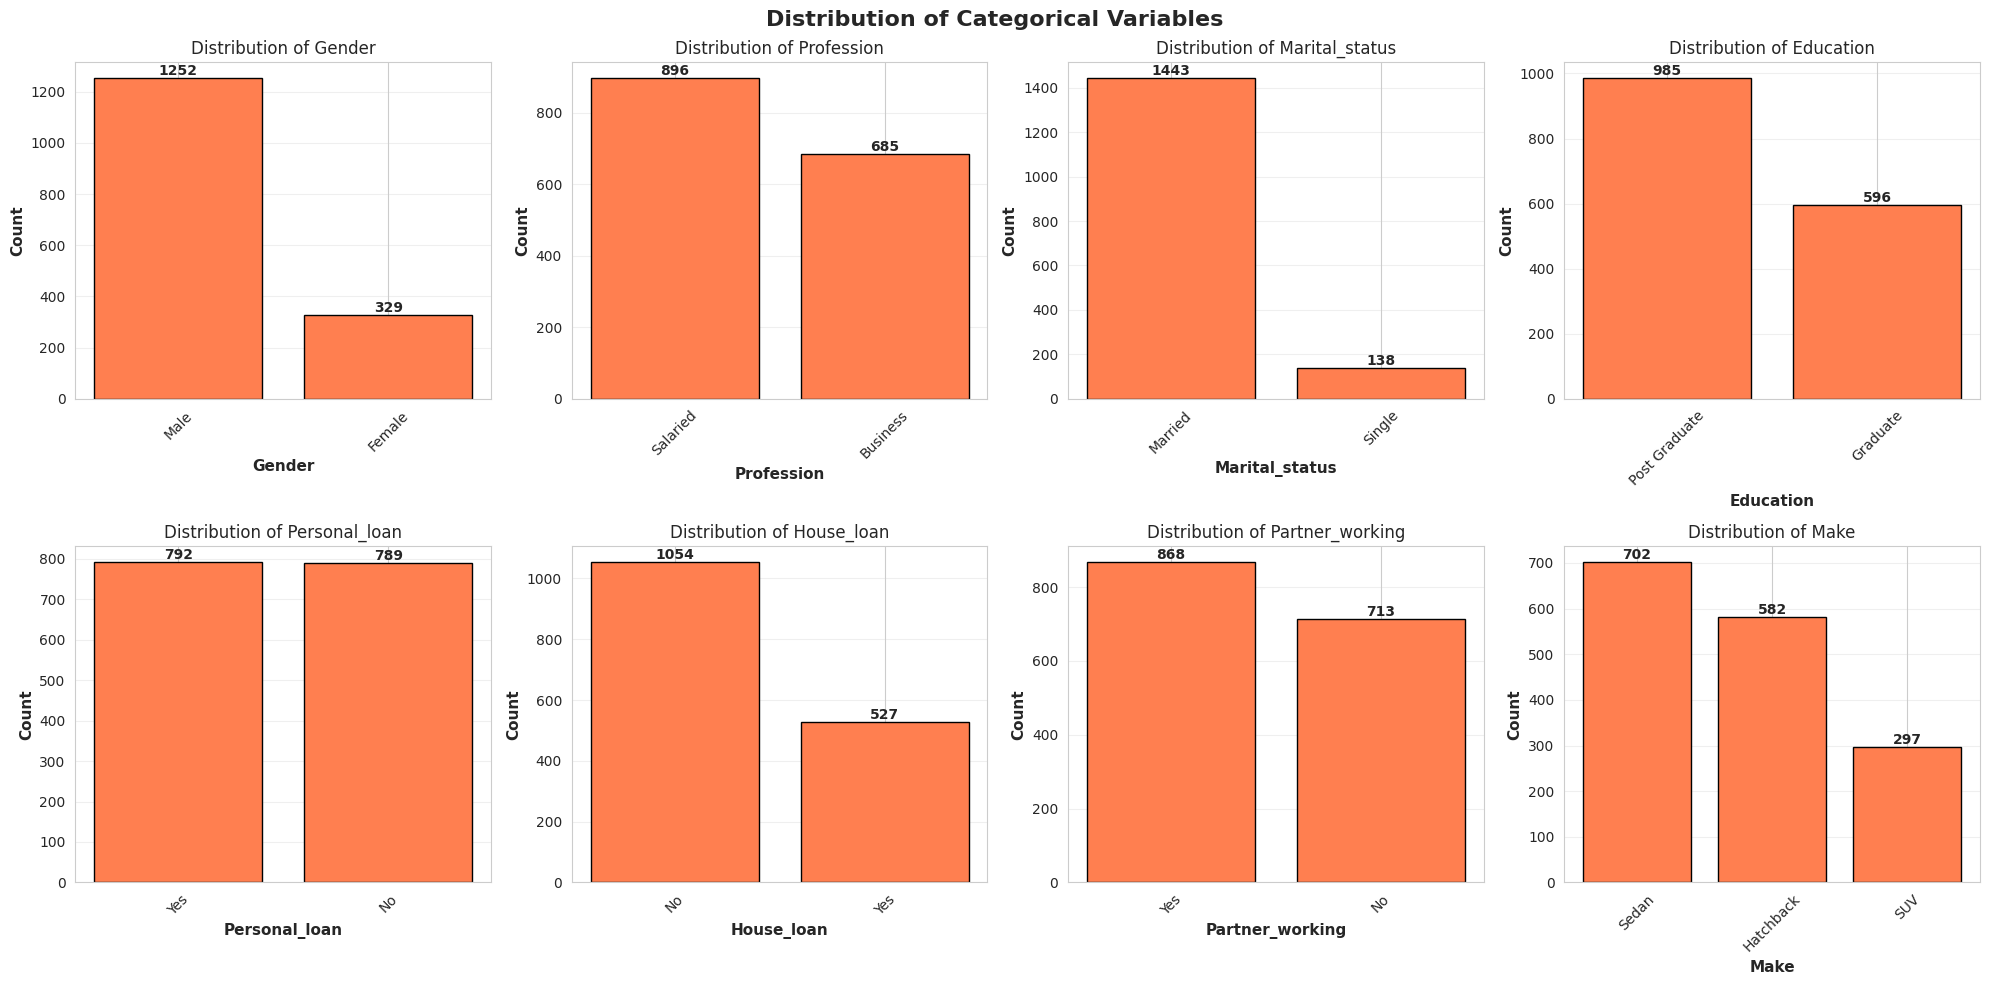

Bar graphs created successfully!


In [ ]:
# Create bar graphs for categorical variables
categorical_cols = ['Gender', 'Profession', 'Marital_status', 'Education',
                   'Personal_loan', 'House_loan', 'Partner_working', 'Make']

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle('Distribution of Categorical Variables', fontsize=16, fontweight='bold')

axes = axes.flatten()

for idx, col in enumerate(categorical_cols):
    # Count values
    counts = df[col].value_counts()

    # Create bar plot
    axes[idx].bar(counts.index, counts.values, color='coral', edgecolor='black')
    axes[idx].set_xlabel(col, fontsize=11, fontweight='bold')
    axes[idx].set_ylabel('Count', fontsize=11, fontweight='bold')
    axes[idx].set_title(f'Distribution of {col}', fontsize=12)
    axes[idx].tick_params(axis='x', rotation=45)
    axes[idx].grid(True, alpha=0.3, axis='y')

    # Add value labels on bars
    for i, v in enumerate(counts.values):
        axes[idx].text(i, v, str(v), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

print("Bar graphs created successfully!")

*  helps to understand the frequency distribution of **categories**

Frequency Tables for Categorical Variables

In [ ]:
for col in categorical_cols:
    print(f"\n{col}:")
    print("-" * 60)

    # Create frequency table with counts and percentages
    freq_table = pd.DataFrame({
        'Count': df[col].value_counts(),
        'Percentage': (df[col].value_counts() / len(df) * 100).round(2)
    })

    print(freq_table)
    print(f"Total unique values: {df[col].nunique()}")


Gender:
------------------------------------------------------------
        Count  Percentage
Gender                   
Male     1252       79.19
Female    329       20.81
Total unique values: 2

Profession:
------------------------------------------------------------
            Count  Percentage
Profession                   
Salaried      896       56.67
Business      685       43.33
Total unique values: 2

Marital_status:
------------------------------------------------------------
                Count  Percentage
Marital_status                   
Married          1443       91.27
Single            138        8.73
Total unique values: 2

Education:
------------------------------------------------------------
               Count  Percentage
Education                       
Post Graduate    985        62.3
Graduate         596        37.7
Total unique values: 2

Personal_loan:
------------------------------------------------------------
               Count  Percentage
Personal_lo

Measure of Variability - Coefficient of Variation

In [ ]:
cv_dict = {}

for col in numerical_cols:
    mean_val = df[col].mean()
    std_val = df[col].std()
    cv = (std_val / mean_val) * 100
    cv_dict[col] = cv

    print(f"{col}:")
    print(f"  Mean: {mean_val:.2f}")
    print(f"  Std Dev: {std_val:.2f}")
    print(f"  CV: {cv:.2f}%")
    print()

# Find most and least inconsistent
most_inconsistent = max(cv_dict, key=cv_dict.get)
least_inconsistent = min(cv_dict, key=cv_dict.get)

Age:
  Mean: 31.92
  Std Dev: 8.43
  CV: 26.40%

No_of_Dependents:
  Mean: 2.46
  Std Dev: 0.94
  CV: 38.39%

Salary:
  Mean: 60392.22
  Std Dev: 14674.83
  CV: 24.30%

Partner_salary:
  Mean: 20585.90
  Std Dev: 18952.94
  CV: 92.07%

Total_salary:
  Mean: 79626.00
  Std Dev: 25545.86
  CV: 32.08%

Price:
  Mean: 35597.72
  Std Dev: 13633.64
  CV: 38.30%



In [ ]:
print(f"MOST INCONSISTENT: {most_inconsistent} (CV = {cv_dict[most_inconsistent]:.2f}%)")
print(f"LEAST INCONSISTENT: {least_inconsistent} (CV = {cv_dict[least_inconsistent]:.2f}%)")

MOST INCONSISTENT: Partner_salary (CV = 92.07%)
LEAST INCONSISTENT: Salary (CV = 24.30%)


* High CV indicates high variability relative to the mean

BIVARIATE ANALYSIS

* Correlation Matrix - Numerical Variables

                   Age  No_of_Dependents  Salary  Partner_salary  \
Age               1.00             -0.19    0.62            0.12   
No_of_Dependents -0.19              1.00   -0.03            0.12   
Salary            0.62             -0.03    1.00            0.07   
Partner_salary    0.12              0.12    0.07            1.00   
Total_salary      0.46              0.09    0.64            0.77   
Price             0.80             -0.14    0.41            0.16   

                  Total_salary  Price  
Age                       0.46   0.80  
No_of_Dependents          0.09  -0.14  
Salary                    0.64   0.41  
Partner_salary            0.77   0.16  
Total_salary              1.00   0.37  
Price                     0.37   1.00  


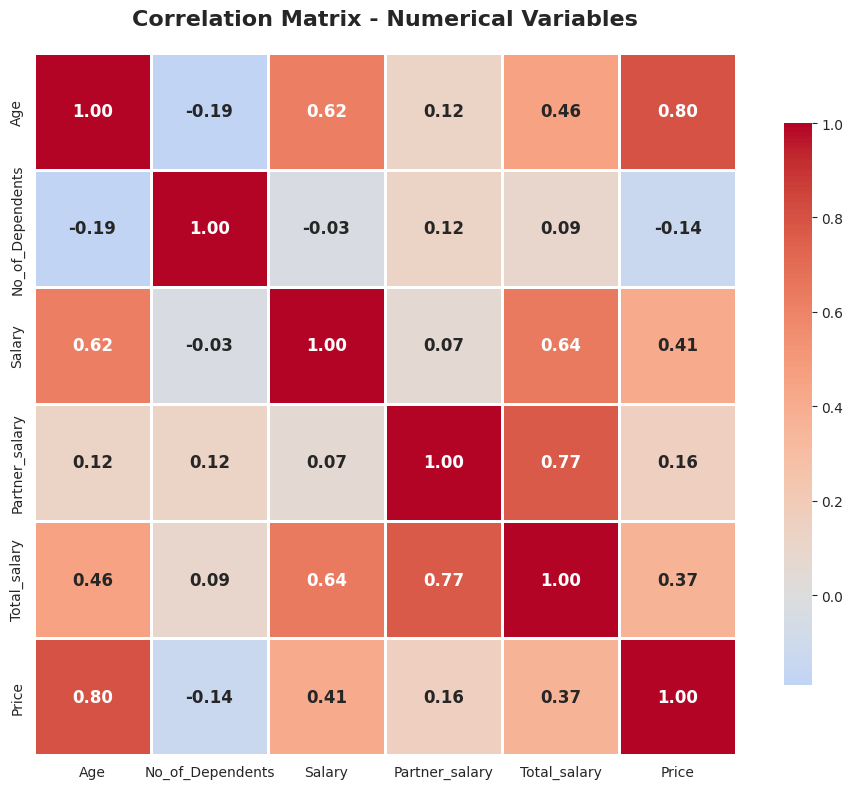


Interpretation:
  +1.00: Perfect positive correlation
  -1.00: Perfect negative correlation
   0.00: No correlation


In [ ]:
correlation_matrix = df[numerical_cols].corr()
print(correlation_matrix.round(2))

# Create heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
            square=True, linewidths=2, cbar_kws={"shrink": 0.8},
            fmt='.2f', annot_kws={'size': 12, 'weight': 'bold'})
plt.title('Correlation Matrix - Numerical Variables', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\nInterpretation:")
print("  +1.00: Perfect positive correlation")
print("  -1.00: Perfect negative correlation")
print("   0.00: No correlation")

Price and Age having high correlation indicating old people buy high priced cars

Scatter Plots - Key Relationships



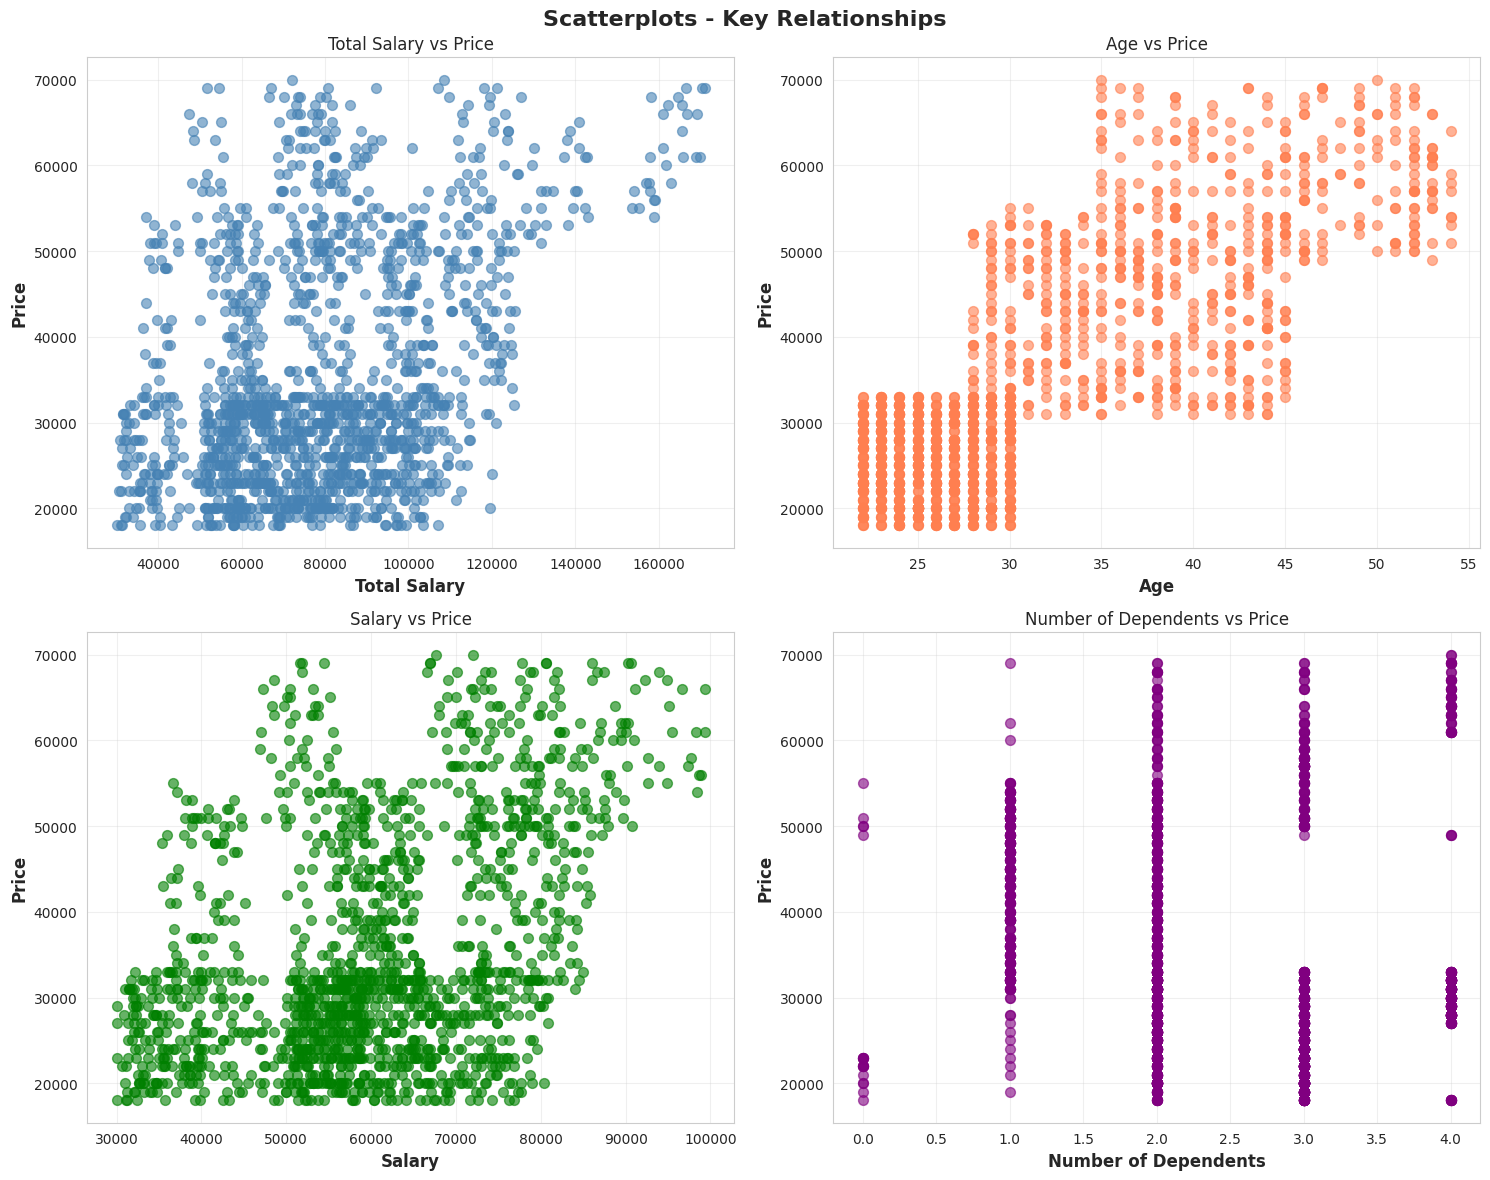

In [ ]:
# Create scatter plots for key relationships
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('Scatterplots - Key Relationships', fontsize=16, fontweight='bold')

# Total Salary vs Price
axes[0, 0].scatter(df['Total_salary'], df['Price'], alpha=0.6, color='steelblue', s=50)
axes[0, 0].set_xlabel('Total Salary', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Price', fontsize=12, fontweight='bold')
axes[0, 0].set_title('Total Salary vs Price', fontsize=12)
axes[0, 0].grid(True, alpha=0.3)

# Age vs Price
axes[0, 1].scatter(df['Age'], df['Price'], alpha=0.6, color='coral', s=50)
axes[0, 1].set_xlabel('Age', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Price', fontsize=12, fontweight='bold')
axes[0, 1].set_title('Age vs Price', fontsize=12)
axes[0, 1].grid(True, alpha=0.3)

# Salary vs Price
axes[1, 0].scatter(df['Salary'], df['Price'], alpha=0.6, color='green', s=50)
axes[1, 0].set_xlabel('Salary', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Price', fontsize=12, fontweight='bold')
axes[1, 0].set_title('Salary vs Price', fontsize=12)
axes[1, 0].grid(True, alpha=0.3)

# No of Dependents vs Price
axes[1, 1].scatter(df['No_of_Dependents'], df['Price'], alpha=0.6, color='purple', s=50)
axes[1, 1].set_xlabel('Number of Dependents', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Price', fontsize=12, fontweight='bold')
axes[1, 1].set_title('Number of Dependents vs Price', fontsize=12)
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

I looked for patterns -
* upward trend = positive relationship,
* downward = negative

Pairplot for Multiple Relationships

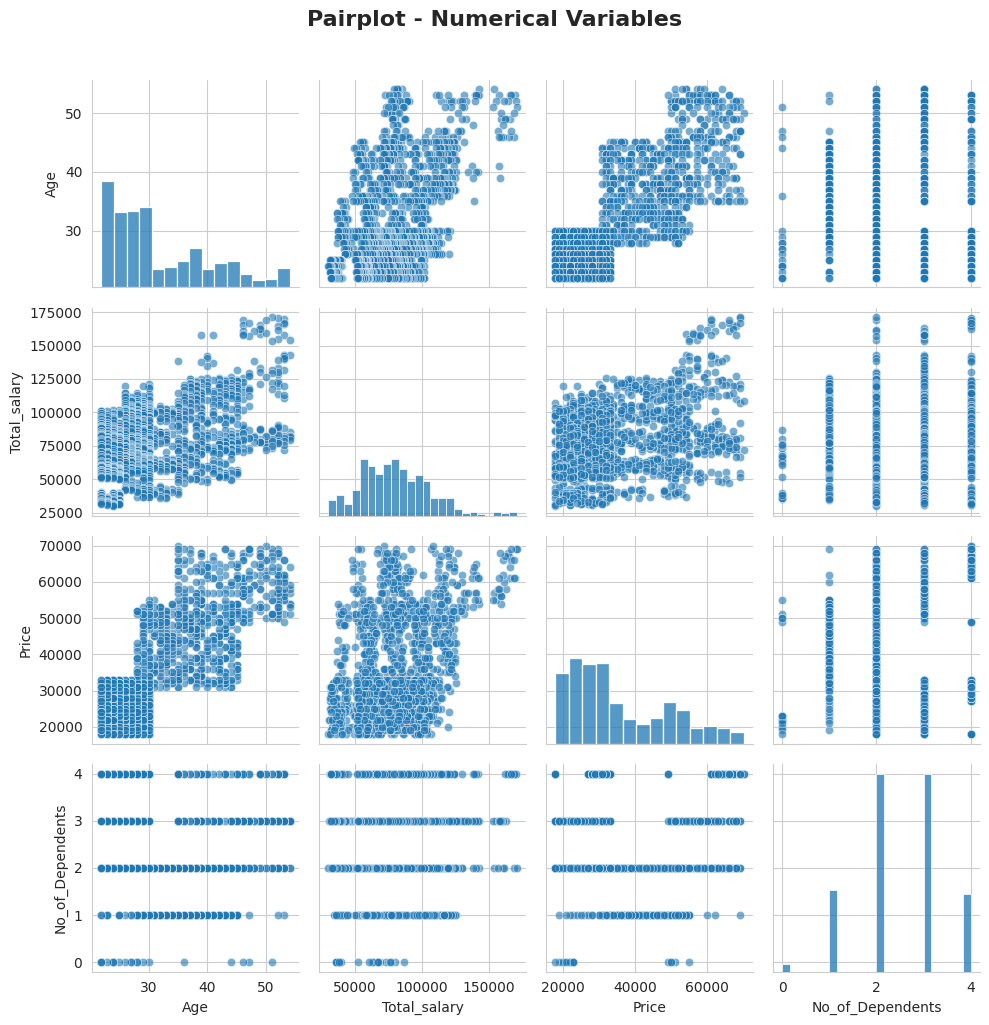

Pairplot created successfully!


In [ ]:
# Create pairplot for selected numerical variables
selected_cols = ['Age', 'Total_salary', 'Price', 'No_of_Dependents']


sns.pairplot(df[selected_cols], diag_kind='hist', plot_kws={'alpha': 0.6})
plt.suptitle('Pairplot - Numerical Variables', y=1.02, fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("Pairplot created successfully!")

* I then analysed Pairplot, which showed distribution (diagonal) and relationships (off-diagonal)

Categorical vs Numerical - GroupBy Analysis
* Analyze how numerical variables vary across categorical groups

In [ ]:
print("\n1. Gender vs Price:")
print("-" * 60)
gender_price = df.groupby('Gender')['Price'].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
print(gender_price.round(2))

print("\n2. Make (Vehicle Type) vs Price:")
print("-" * 60)
make_price = df.groupby('Make')['Price'].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
print(make_price.round(2))

print("\n3. Profession vs Price:")
print("-" * 60)
profession_price = df.groupby('Profession')['Price'].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
print(profession_price.round(2))

print("\n4. Education vs Price:")
print("-" * 60)
education_price = df.groupby('Education')['Price'].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
print(education_price.round(2))


1. Gender vs Price:
------------------------------------------------------------
        count      mean   median       std    min    max
Gender                                                  
Female    329  47705.17  49000.0  11244.84  20000  69000
Male     1252  32416.13  29000.0  12366.25  18000  70000

2. Make (Vehicle Type) vs Price:
------------------------------------------------------------
           count      mean   median       std    min    max
Make                                                       
Hatchback    582  26474.23  27000.0   4290.47  18000  33000
SUV          297  55824.92  57000.0   9218.24  31000  70000
Sedan        702  34603.99  33000.0  11152.16  18000  55000

3. Profession vs Price:
------------------------------------------------------------
            count      mean   median       std    min    max
Profession                                                  
Business      685  33353.28  30000.0  12911.33  18000  70000
Salaried      896  37313.6

Boxplots for Categorical vs Numerical

* I then visualized price distribution across categorical groups


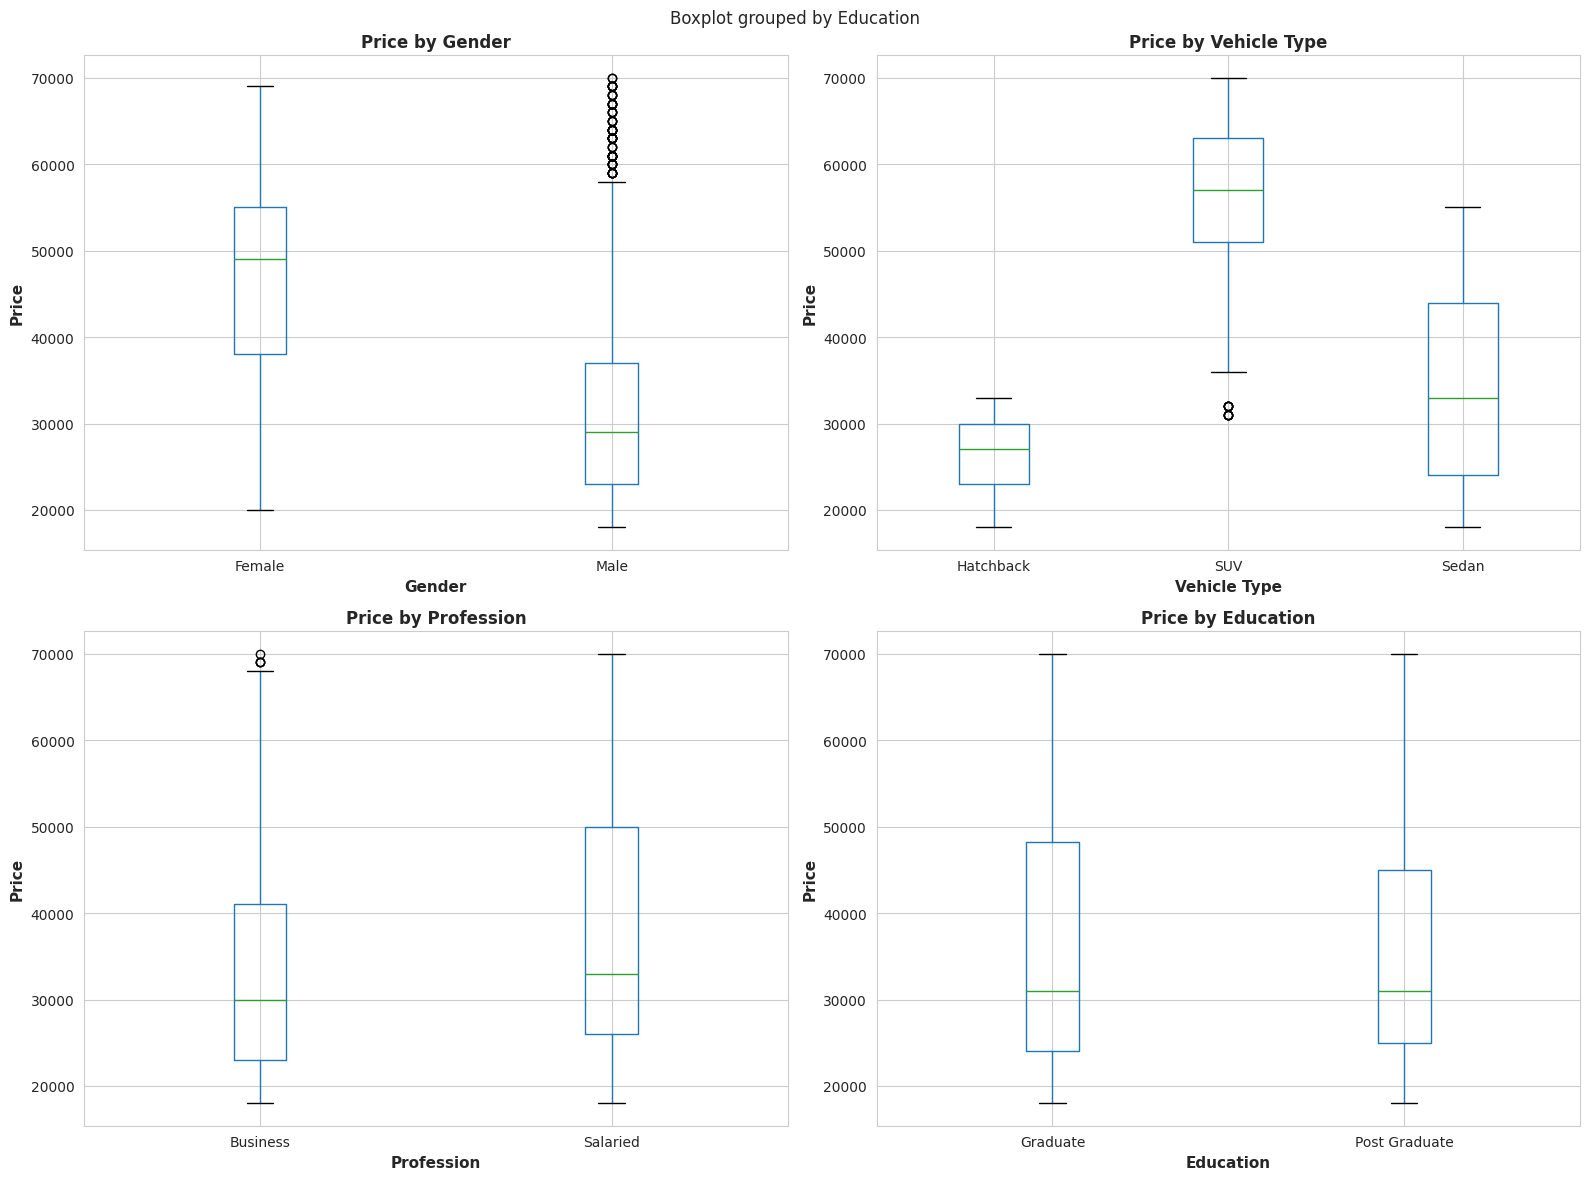

In [ ]:
# Create boxplots for categorical vs numerical analysis
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Price Distribution by Categorical Variables', fontsize=16, fontweight='bold')

# Gender vs Price
df.boxplot(column='Price', by='Gender', ax=axes[0, 0])
axes[0, 0].set_title('Price by Gender', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Gender', fontsize=11, fontweight='bold')
axes[0, 0].set_ylabel('Price', fontsize=11, fontweight='bold')
plt.sca(axes[0, 0])
plt.xticks(rotation=0)

# Make vs Price
df.boxplot(column='Price', by='Make', ax=axes[0, 1])
axes[0, 1].set_title('Price by Vehicle Type', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Vehicle Type', fontsize=11, fontweight='bold')
axes[0, 1].set_ylabel('Price', fontsize=11, fontweight='bold')

# Profession vs Price
df.boxplot(column='Price', by='Profession', ax=axes[1, 0])
axes[1, 0].set_title('Price by Profession', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Profession', fontsize=11, fontweight='bold')
axes[1, 0].set_ylabel('Price', fontsize=11, fontweight='bold')

# Education vs Price
df.boxplot(column='Price', by='Education', ax=axes[1, 1])
axes[1, 1].set_title('Price by Education', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Education', fontsize=11, fontweight='bold')
axes[1, 1].set_ylabel('Price', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

KEY BUSINESS QUESTIONS



1.   Q1 - Do men prefer SUVs more than women?




Cross-tabulation (Counts):
Make    Hatchback  SUV  Sedan
Gender                       
Female         15  173    141
Male          567  124    561

Cross-tabulation (Percentages):
Make    Hatchback    SUV  Sedan
Gender                         
Female       4.56  52.58  42.86
Male        45.29   9.90  44.81


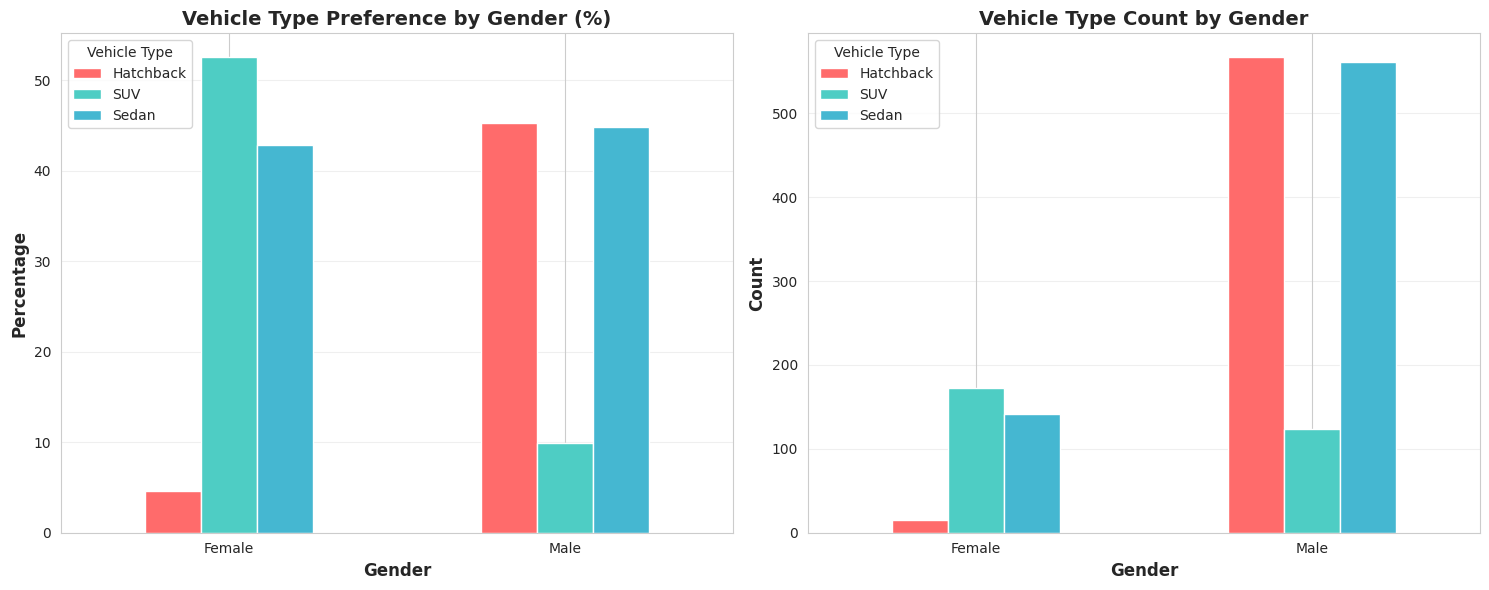


INSIGHTS:
Male SUV preference: 9.90%
Female SUV preference: 52.58%
Difference: -42.68 percentage points


In [ ]:
# Create cross-tabulation
gender_make_crosstab = pd.crosstab(df['Gender'], df['Make'])
print("\nCross-tabulation (Counts):")
print(gender_make_crosstab)

# Calculate percentages
gender_make_pct = pd.crosstab(df['Gender'], df['Make'], normalize='index') * 100
print("\nCross-tabulation (Percentages):")
print(gender_make_pct.round(2))

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Stacked bar chart (percentages)
gender_make_pct.plot(kind='bar', ax=axes[0], color=['#FF6B6B', '#4ECDC4', '#45B7D1'])
axes[0].set_title('Vehicle Type Preference by Gender (%)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Gender', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Percentage', fontsize=12, fontweight='bold')
axes[0].legend(title='Vehicle Type', fontsize=10)
axes[0].tick_params(axis='x', rotation=0)
axes[0].grid(True, alpha=0.3, axis='y')

# Count plot
gender_make_crosstab.plot(kind='bar', ax=axes[1], color=['#FF6B6B', '#4ECDC4', '#45B7D1'])
axes[1].set_title('Vehicle Type Count by Gender', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Gender', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Count', fontsize=12, fontweight='bold')
axes[1].legend(title='Vehicle Type', fontsize=10)
axes[1].tick_params(axis='x', rotation=0)
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Print insights
print("\n" + "="*60)
print("INSIGHTS:")
male_suv_pct = gender_make_pct.loc['Male', 'SUV']
female_suv_pct = gender_make_pct.loc['Female', 'SUV']
difference = male_suv_pct - female_suv_pct

print(f"Male SUV preference: {male_suv_pct:.2f}%")
print(f"Female SUV preference: {female_suv_pct:.2f}%")
print(f"Difference: {difference:.2f} percentage points")


NO, women prefer SUVs more than men



   
2.   Q2 - What is the likelihood of a salaried person buying a Sedan?

* to calculate conditional probability



Total salaried individuals: 896
Salaried who bought Sedan: 396

Probability P(Sedan | Salaried) = 396/896
P(Sedan | Salaried) = 0.4420 or 44.20%

Detailed breakdown by Profession:
Make        Hatchback    SUV  Sedan
Profession                         
Business        42.34  12.99  44.67
Salaried        32.59  23.21  44.20


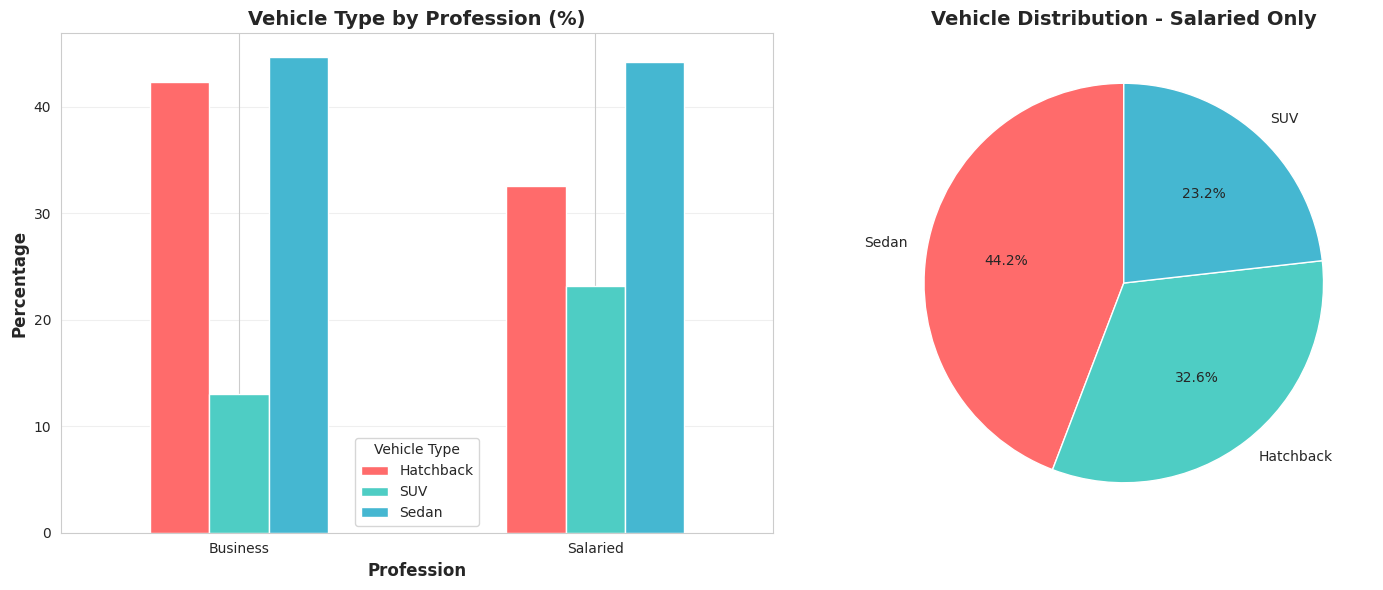


ANSWER: The likelihood is 44.20%
Approximately 44 out of 100 salaried individuals buy Sedans


In [ ]:
# Filter salaried individuals
salaried = df[df['Profession'] == 'Salaried']
total_salaried = len(salaried)

# Filter salaried who bought sedan
salaried_sedan = salaried[salaried['Make'] == 'Sedan']
count_salaried_sedan = len(salaried_sedan)

# Calculate probability
probability = count_salaried_sedan / total_salaried

print(f"\nTotal salaried individuals: {total_salaried}")
print(f"Salaried who bought Sedan: {count_salaried_sedan}")
print(f"\nProbability P(Sedan | Salaried) = {count_salaried_sedan}/{total_salaried}")
print(f"P(Sedan | Salaried) = {probability:.4f} or {probability*100:.2f}%")

# Profession vs Make breakdown
print("\nDetailed breakdown by Profession:")
profession_make = pd.crosstab(df['Profession'], df['Make'], normalize='index') * 100
print(profession_make.round(2))

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Bar chart
profession_make.plot(kind='bar', ax=axes[0], color=['#FF6B6B', '#4ECDC4', '#45B7D1'])
axes[0].set_title('Vehicle Type by Profession (%)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Profession', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Percentage', fontsize=12, fontweight='bold')
axes[0].legend(title='Vehicle Type')
axes[0].tick_params(axis='x', rotation=0)
axes[0].grid(True, alpha=0.3, axis='y')

# Pie chart for salaried only
salaried_make = salaried['Make'].value_counts()
axes[1].pie(salaried_make, labels=salaried_make.index, autopct='%1.1f%%',
            startangle=90, colors=['#FF6B6B', '#4ECDC4', '#45B7D1'])
axes[1].set_title('Vehicle Distribution - Salaried Only', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print(f"ANSWER: The likelihood is {probability*100:.2f}%")
print(f"Approximately {int(probability*100)} out of 100 salaried individuals buy Sedans")




3.   Q3 - What evidence or data supports Sheldon Cooper's claim that a salaried male is an easier target for a SUV sale over a Sedan sale?





Total salaried males: 672

Vehicle purchases by salaried males:
Make
Sedan        305
Hatchback    277
SUV           90
Name: count, dtype: int64

Percentage distribution:
Make
Sedan        45.39
Hatchback    41.22
SUV          13.39
Name: count, dtype: float64

P(SUV | Salaried Male) = 0.1339 or 13.39%
P(Sedan | Salaried Male) = 0.4539 or 45.39%

Ratio (SUV:Sedan) = 0.30:1
Salaried males are 0.30x more likely to buy SUV than Sedan


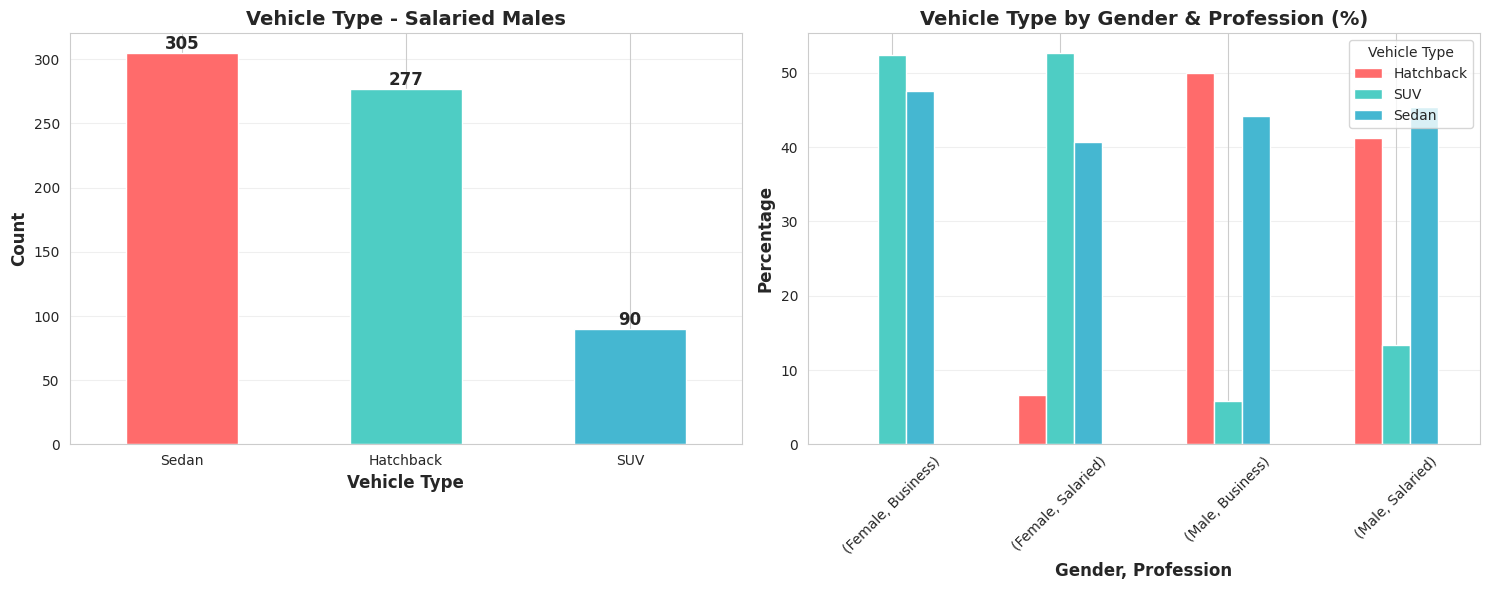


VERDICT:
✗ CLAIM REJECTED: Salaried males prefer Sedan over SUV


In [ ]:
# Filter salaried males using multiple conditions
salaried_male = df[(df['Profession'] == 'Salaried') & (df['Gender'] == 'Male')]

total_salaried_male = len(salaried_male)
print(f"\nTotal salaried males: {total_salaried_male}")

# Count by vehicle type
salaried_male_make = salaried_male['Make'].value_counts()
print(f"\nVehicle purchases by salaried males:")
print(salaried_male_make)

# Calculate percentages
salaried_male_pct = (salaried_male_make / total_salaried_male) * 100
print(f"\nPercentage distribution:")
print(salaried_male_pct.round(2))

# Extract SUV and Sedan values
suv_count = salaried_male_make.get('SUV', 0)
sedan_count = salaried_male_make.get('Sedan', 0)

prob_suv = (suv_count / total_salaried_male)
prob_sedan = (sedan_count / total_salaried_male)

print(f"\nP(SUV | Salaried Male) = {prob_suv:.4f} or {prob_suv*100:.2f}%")
print(f"P(Sedan | Salaried Male) = {prob_sedan:.4f} or {prob_sedan*100:.2f}%")

# Calculate ratio
if sedan_count > 0:
    ratio = suv_count / sedan_count
    print(f"\nRatio (SUV:Sedan) = {ratio:.2f}:1")
    print(f"Salaried males are {ratio:.2f}x more likely to buy SUV than Sedan")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Bar chart for salaried males
salaried_male_make.plot(kind='bar', ax=axes[0], color=['#FF6B6B', '#4ECDC4', '#45B7D1'])
axes[0].set_title('Vehicle Type - Salaried Males', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Vehicle Type', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Count', fontsize=12, fontweight='bold')
axes[0].tick_params(axis='x', rotation=0)
axes[0].grid(True, alpha=0.3, axis='y')

# Add value labels
for i, v in enumerate(salaried_male_make.values):
    axes[0].text(i, v, str(v), ha='center', va='bottom', fontweight='bold', fontsize=12)

# Comparison across segments
gender_prof_make = df.groupby(['Gender', 'Profession'])['Make'].value_counts(normalize=True).unstack() * 100
gender_prof_make.plot(kind='bar', ax=axes[1], color=['#FF6B6B', '#4ECDC4', '#45B7D1'])
axes[1].set_title('Vehicle Type by Gender & Profession (%)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Gender, Profession', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Percentage', fontsize=12, fontweight='bold')
axes[1].legend(title='Vehicle Type')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Final verdict
print("\n" + "="*60)
print("VERDICT:")
if prob_suv > prob_sedan:
    print("✓ CLAIM CONFIRMED: Salaried males are easier to target for SUV than Sedan")
    print(f"  Evidence: {prob_suv*100:.1f}% choose SUV vs {prob_sedan*100:.1f}% choose Sedan")
else:
    print("✗ CLAIM REJECTED: Salaried males prefer Sedan over SUV")




4.  Q4 How does the amount spent on purchasing automobiles vary by gender?




Price statistics by gender:
        count      mean   median       std    min    max
Gender                                                  
Female    329  47705.17  49000.0  11244.84  20000  69000
Male     1252  32416.13  29000.0  12366.25  18000  70000

KEY INSIGHTS:
Average spending - Male: ₹32,416
Average spending - Female: ₹47,705
Difference: ₹-15,289 (-32.05%)


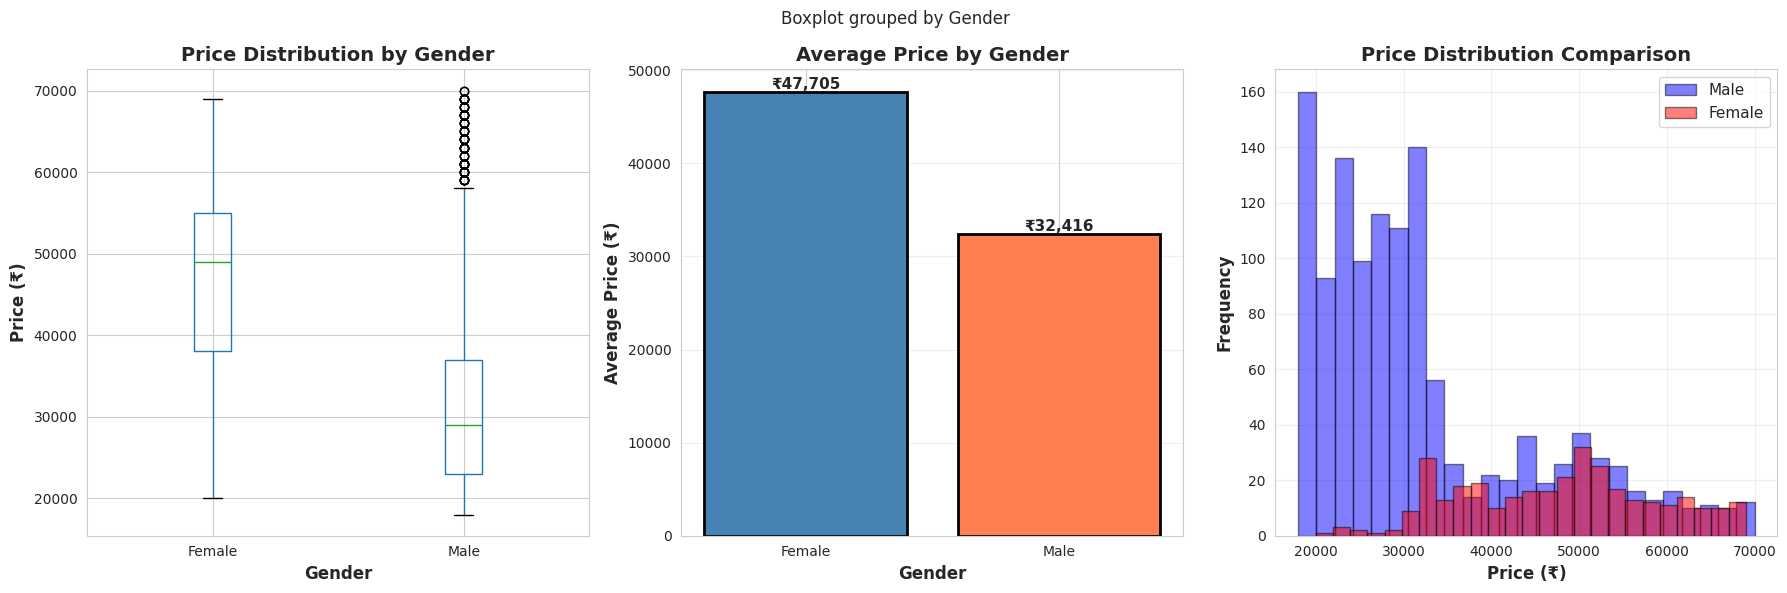


Spending range distribution:
Price_Range  Low (<30k)  Medium (30-50k)  High (>50k)
Gender                                               
Female             3.04            53.50        43.47
Male              57.11            30.43        12.46

CONCLUSION: Females spend 32.0% MORE on average than males


In [ ]:
# Group by gender and analyze price
gender_price_stats = df.groupby('Gender')['Price'].agg(['count', 'mean', 'median',
                                                          'std', 'min', 'max'])
print("\nPrice statistics by gender:")
print(gender_price_stats.round(2))

# Calculate additional insights
male_avg = df[df['Gender'] == 'Male']['Price'].mean()
female_avg = df[df['Gender'] == 'Female']['Price'].mean()
difference = male_avg - female_avg
pct_difference = (difference / female_avg) * 100

print("\n" + "="*60)
print("KEY INSIGHTS:")
print(f"Average spending - Male: ₹{male_avg:,.0f}")
print(f"Average spending - Female: ₹{female_avg:,.0f}")
print(f"Difference: ₹{difference:,.0f} ({pct_difference:+.2f}%)")

# Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Boxplot
df.boxplot(column='Price', by='Gender', ax=axes[0])
axes[0].set_title('Price Distribution by Gender', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Gender', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Price (₹)', fontsize=12, fontweight='bold')
plt.sca(axes[0])
plt.xticks(rotation=0)

# Bar chart - mean price
gender_means = df.groupby('Gender')['Price'].mean()
axes[1].bar(gender_means.index, gender_means.values, color=['steelblue', 'coral'],
            edgecolor='black', linewidth=2)
axes[1].set_title('Average Price by Gender', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Gender', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Average Price (₹)', fontsize=12, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')

# Add value labels
for i, v in enumerate(gender_means.values):
    axes[1].text(i, v, f'₹{v:,.0f}', ha='center', va='bottom',
                 fontweight='bold', fontsize=11)

# Histogram comparison
male_prices = df[df['Gender'] == 'Male']['Price']
female_prices = df[df['Gender'] == 'Female']['Price']

axes[2].hist(male_prices, alpha=0.5, label='Male', bins=25, color='blue', edgecolor='black')
axes[2].hist(female_prices, alpha=0.5, label='Female', bins=25, color='red', edgecolor='black')
axes[2].set_xlabel('Price (₹)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Frequency', fontsize=12, fontweight='bold')
axes[2].set_title('Price Distribution Comparison', fontsize=14, fontweight='bold')
axes[2].legend(fontsize=11)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Spending ranges analysis
print("\nSpending range distribution:")
df['Price_Range'] = pd.cut(df['Price'], bins=[0, 30000, 50000, 100000],
                            labels=['Low (<30k)', 'Medium (30-50k)', 'High (>50k)'])

price_range_gender = pd.crosstab(df['Gender'], df['Price_Range'], normalize='index') * 100
print(price_range_gender.round(2))

print("\n" + "="*60)
if male_avg > female_avg:
    print(f"CONCLUSION: Males spend {pct_difference:.1f}% MORE on average than females")
else:
    print(f"CONCLUSION: Females spend {abs(pct_difference):.1f}% MORE on average than males")



5.   Q5 How much money was spent on purchasing automobiles by individuals who took a personal loan?




Price statistics by Personal Loan status:
                  Price                                                 
                    sum count      mean   median       std    min    max
Personal_loan                                                           
No             28990000   789  36742.71  32000.0  14534.34  18000  70000
Yes            27290000   792  34457.07  31000.0  12578.78  18000  70000

SUMMARY:
Total spent by people WITH personal loan: ₹27,290,000
Total spent by people WITHOUT personal loan: ₹28,990,000

Count WITH loan: 792 customers
Count WITHOUT loan: 789 customers

Average WITH loan: ₹34,457
Average WITHOUT loan: ₹36,743

Difference: ₹-2,286 (-6.22%)


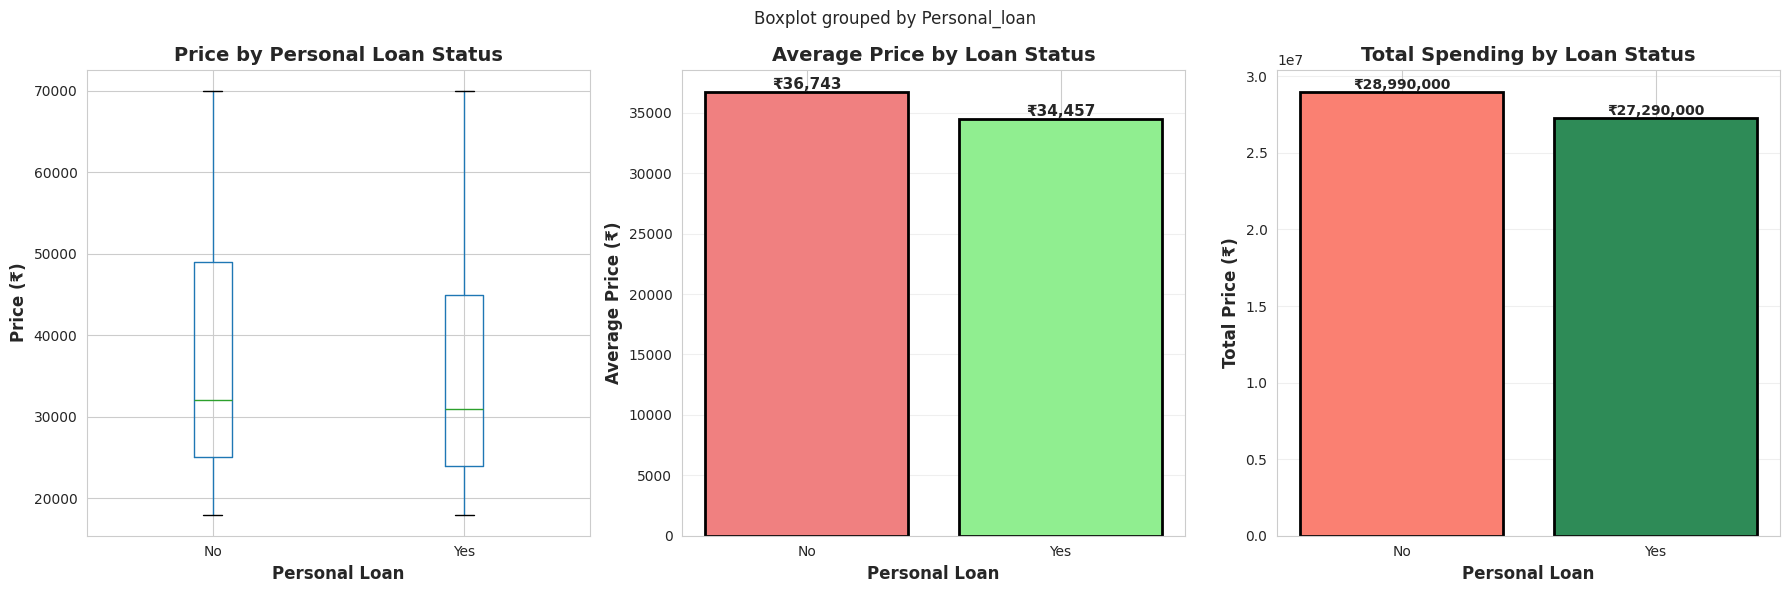


Vehicle type distribution by loan status:
Make           Hatchback    SUV  Sedan
Personal_loan                         
No                 36.88  22.94  40.18
Yes                36.74  14.65  48.61

ANSWER: Individuals with personal loans spent ₹27,290,000 in total


In [ ]:

# Group by personal loan status
loan_analysis = df.groupby('Personal_loan').agg({
    'Price': ['sum', 'count', 'mean', 'median', 'std', 'min', 'max']
})

print("\nPrice statistics by Personal Loan status:")
print(loan_analysis.round(2))

# Calculate totals
total_with_loan = df[df['Personal_loan'] == 'Yes']['Price'].sum()
total_without_loan = df[df['Personal_loan'] == 'No']['Price'].sum()
count_with_loan = len(df[df['Personal_loan'] == 'Yes'])
count_without_loan = len(df[df['Personal_loan'] == 'No'])
avg_with_loan = df[df['Personal_loan'] == 'Yes']['Price'].mean()
avg_without_loan = df[df['Personal_loan'] == 'No']['Price'].mean()

print("\n" + "="*60)
print("SUMMARY:")
print(f"Total spent by people WITH personal loan: ₹{total_with_loan:,.0f}")
print(f"Total spent by people WITHOUT personal loan: ₹{total_without_loan:,.0f}")
print(f"\nCount WITH loan: {count_with_loan} customers")
print(f"Count WITHOUT loan: {count_without_loan} customers")
print(f"\nAverage WITH loan: ₹{avg_with_loan:,.0f}")
print(f"Average WITHOUT loan: ₹{avg_without_loan:,.0f}")

difference = avg_with_loan - avg_without_loan
pct_diff = (difference / avg_without_loan) * 100
print(f"\nDifference: ₹{difference:,.0f} ({pct_diff:+.2f}%)")

# Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Boxplot
df.boxplot(column='Price', by='Personal_loan', ax=axes[0])
axes[0].set_title('Price by Personal Loan Status', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Personal Loan', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Price (₹)', fontsize=12, fontweight='bold')
plt.sca(axes[0])
plt.xticks(rotation=0)

# Bar chart - average spending
loan_means = df.groupby('Personal_loan')['Price'].mean()
axes[1].bar(loan_means.index, loan_means.values, color=['lightcoral', 'lightgreen'],
            edgecolor='black', linewidth=2)
axes[1].set_title('Average Price by Loan Status', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Personal Loan', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Average Price (₹)', fontsize=12, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')

for i, v in enumerate(loan_means.values):
    axes[1].text(i, v, f'₹{v:,.0f}', ha='center', va='bottom',
                 fontweight='bold', fontsize=11)

# Bar chart - total spending
loan_totals = df.groupby('Personal_loan')['Price'].sum()
axes[2].bar(loan_totals.index, loan_totals.values, color=['salmon', 'seagreen'],
            edgecolor='black', linewidth=2)
axes[2].set_title('Total Spending by Loan Status', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Personal Loan', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Total Price (₹)', fontsize=12, fontweight='bold')
axes[2].grid(True, alpha=0.3, axis='y')

for i, v in enumerate(loan_totals.values):
    axes[2].text(i, v, f'₹{v:,.0f}', ha='center', va='bottom',
                 fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

# Vehicle type distribution by loan status
print("\nVehicle type distribution by loan status:")
loan_make = pd.crosstab(df['Personal_loan'], df['Make'], normalize='index') * 100
print(loan_make.round(2))

print("\n" + "="*60)
print("ANSWER: Individuals with personal loans spent ₹{:,.0f} in total".format(total_with_loan))


6.   Q6  How does having a working partner influence the purchase of higher-priced cars?





Statistics by Partner Working Status:
                Price                                            Total_salary  \
                count      mean   median       std    min    max         mean   
Partner_working                                                                 
No                713  36000.00  31000.0  13817.73  18000  70000     60527.21   
Yes               868  35267.28  31000.0  13479.53  18000  70000     95314.29   

                          
                  median  
Partner_working           
No               60100.0  
Yes              94250.0  

KEY FINDINGS:
Average price WITH working partner: ₹35,267
Average price WITHOUT working partner: ₹36,000
Price difference: ₹-733 (-2.0%)

Average total salary WITH working partner: ₹95,314
Average total salary WITHOUT working partner: ₹60,527
Salary difference: ₹34,787

High-priced car threshold (75th percentile): ₹47,000

Percentage buying high-priced cars:
Is_High_Price    False  True 
Partner_working             

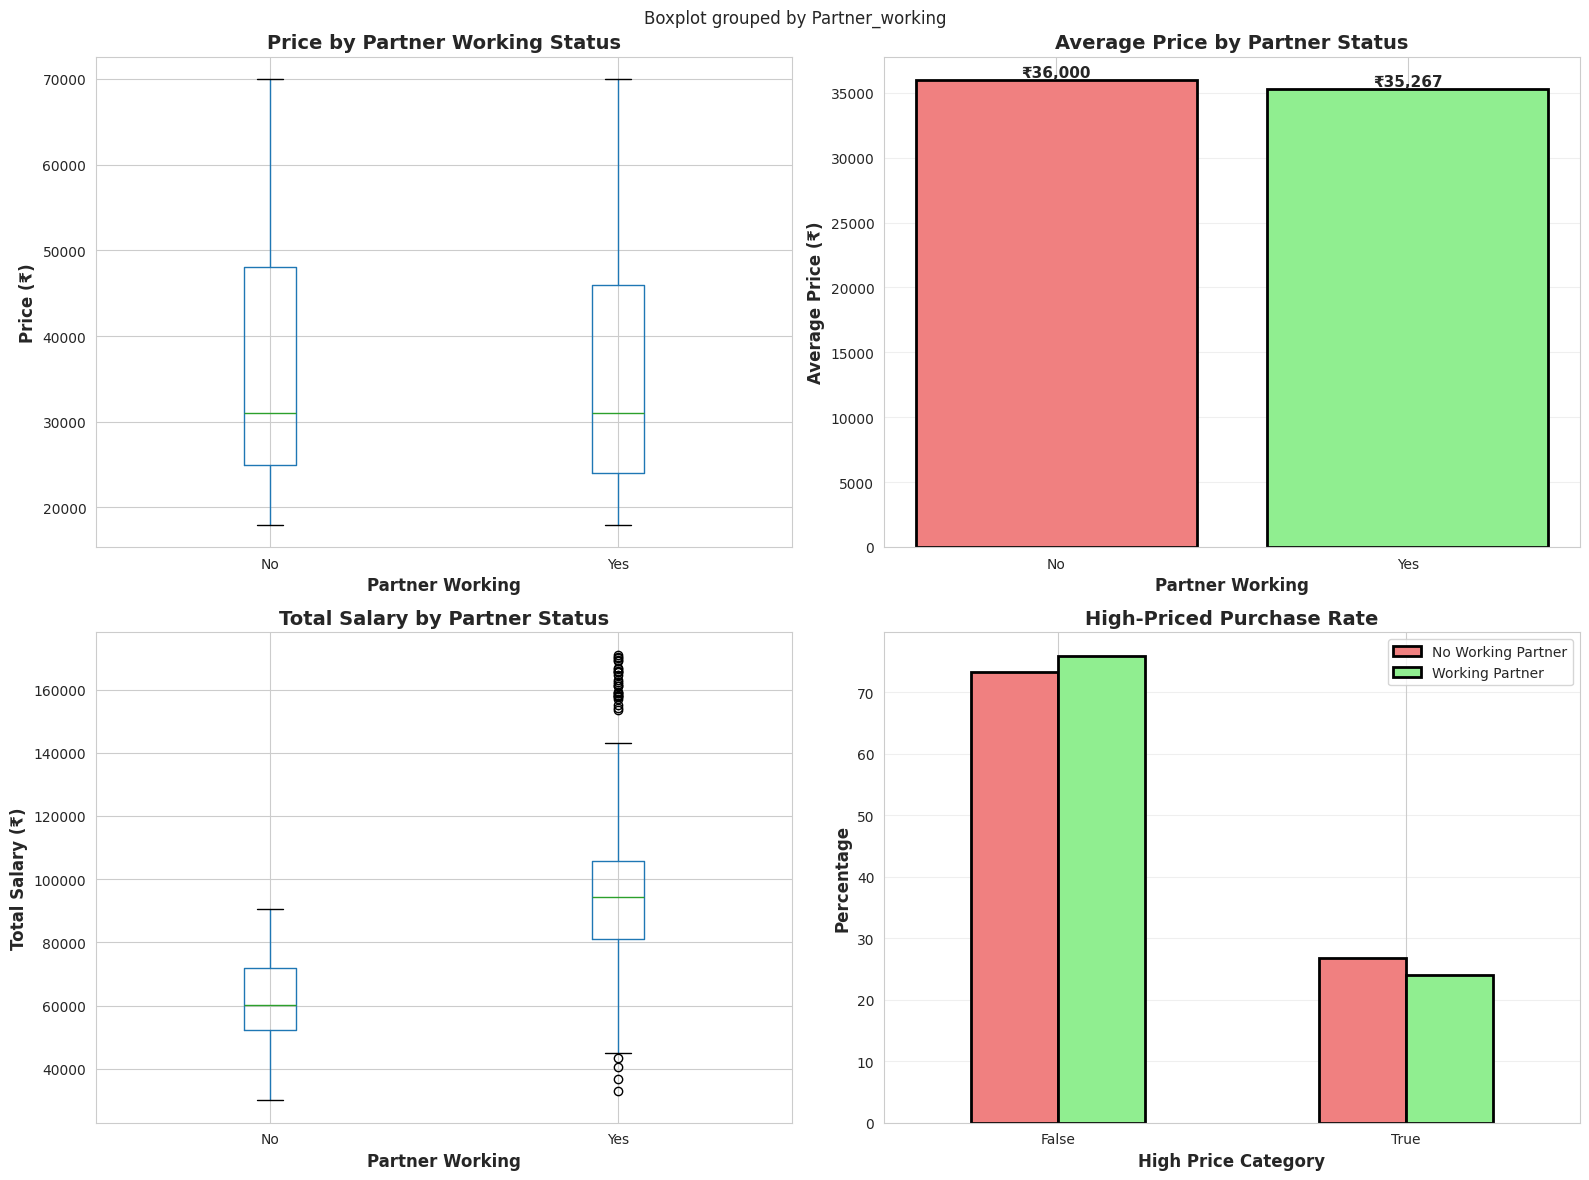


Vehicle type preference by partner status:
Make             Hatchback    SUV  Sedan
Partner_working                         
No                   39.41  20.20  40.39
Yes                  34.68  17.63  47.70

CONCLUSION:
Working partner has a STRONG POSITIVE influence on car purchases
Customers with working partners spend -2.0% MORE on average
They are 0.9x more likely to buy high-priced cars


In [ ]:

# Analyze by partner working status
partner_price_stats = df.groupby('Partner_working').agg({
    'Price': ['count', 'mean', 'median', 'std', 'min', 'max'],
    'Total_salary': ['mean', 'median']
})

print("\nStatistics by Partner Working Status:")
print(partner_price_stats.round(2))

# Calculate key metrics
with_partner = df[df['Partner_working'] == 'Yes']
without_partner = df[df['Partner_working'] == 'No']

avg_price_with = with_partner['Price'].mean()
avg_price_without = without_partner['Price'].mean()
avg_salary_with = with_partner['Total_salary'].mean()
avg_salary_without = without_partner['Total_salary'].mean()

price_difference = avg_price_with - avg_price_without
price_pct_diff = (price_difference / avg_price_without) * 100

print("\n" + "="*60)
print("KEY FINDINGS:")
print(f"Average price WITH working partner: ₹{avg_price_with:,.0f}")
print(f"Average price WITHOUT working partner: ₹{avg_price_without:,.0f}")
print(f"Price difference: ₹{price_difference:,.0f} ({price_pct_diff:+.1f}%)")
print()
print(f"Average total salary WITH working partner: ₹{avg_salary_with:,.0f}")
print(f"Average total salary WITHOUT working partner: ₹{avg_salary_without:,.0f}")
print(f"Salary difference: ₹{avg_salary_with - avg_salary_without:,.0f}")

# Define high-priced cars (top 25%)
high_price_threshold = df['Price'].quantile(0.75)
print(f"\nHigh-priced car threshold (75th percentile): ₹{high_price_threshold:,.0f}")

# Create high price indicator
df['Is_High_Price'] = df['Price'] >= high_price_threshold

# Analyze high-priced purchases
high_price_partner = pd.crosstab(df['Partner_working'], df['Is_High_Price'],
                                 normalize='index') * 100

print("\nPercentage buying high-priced cars:")
print(high_price_partner.round(2))

high_pct_with = high_price_partner.loc['Yes', True]
high_pct_without = high_price_partner.loc['No', True]

print(f"\nWith working partner: {high_pct_with:.1f}% buy high-priced cars")
print(f"Without working partner: {high_pct_without:.1f}% buy high-priced cars")
print(f"Ratio: {high_pct_with/high_pct_without:.2f}x more likely")

# Visualizations
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Boxplot - Price by partner status
df.boxplot(column='Price', by='Partner_working', ax=axes[0, 0])
axes[0, 0].set_title('Price by Partner Working Status', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Partner Working', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Price (₹)', fontsize=12, fontweight='bold')
plt.sca(axes[0, 0])
plt.xticks(rotation=0)

# Bar chart - Average price
partner_means = df.groupby('Partner_working')['Price'].mean()
axes[0, 1].bar(partner_means.index, partner_means.values,
               color=['lightcoral', 'lightgreen'], edgecolor='black', linewidth=2)
axes[0, 1].set_title('Average Price by Partner Status', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Partner Working', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Average Price (₹)', fontsize=12, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3, axis='y')

for i, v in enumerate(partner_means.values):
    axes[0, 1].text(i, v, f'₹{v:,.0f}', ha='center', va='bottom',
                    fontweight='bold', fontsize=11)

# Boxplot - Total salary by partner status
df.boxplot(column='Total_salary', by='Partner_working', ax=axes[1, 0])
axes[1, 0].set_title('Total Salary by Partner Status', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Partner Working', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Total Salary (₹)', fontsize=12, fontweight='bold')
plt.sca(axes[1, 0])
plt.xticks(rotation=0)

# Stacked bar - High price purchase rate
high_price_partner.T.plot(kind='bar', ax=axes[1, 1],
                          color=['lightcoral', 'lightgreen'],
                          edgecolor='black', linewidth=2)
axes[1, 1].set_title('High-Priced Purchase Rate', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('High Price Category', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Percentage', fontsize=12, fontweight='bold')
axes[1, 1].legend(['No Working Partner', 'Working Partner'], fontsize=10)
axes[1, 1].tick_params(axis='x', rotation=0)
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Vehicle type preference by partner status
print("\nVehicle type preference by partner status:")
partner_make = pd.crosstab(df['Partner_working'], df['Make'], normalize='index') * 100
print(partner_make.round(2))

print("\n" + "="*60)
print("CONCLUSION:")
print(f"Working partner has a STRONG POSITIVE influence on car purchases")
print(f"Customers with working partners spend {price_pct_diff:.1f}% MORE on average")
print(f"They are {high_pct_with/high_pct_without:.1f}x more likely to buy high-priced cars")

ADDITIONAL INSIGHTS
* Summary Statistics Table



In [ ]:
# Create summary dictionary
summary_data = {
    'Metric': [
        'Total Customers',
        'Average Age',
        'Average Salary',
        'Average Total Salary',
        'Average Price',
        'Most Popular Vehicle',
        'SUV Market Share (%)',
        'Sedan Market Share (%)',
        'Hatchback Market Share (%)',
        'Customers with Working Partner (%)',
        'Customers with Personal Loan (%)',
        'Male Customers (%)',
        'Female Customers (%)',
        'Salaried Professionals (%)',
        'Business Professionals (%)'
    ],
    'Value': [
        len(df),
        f"{df['Age'].mean():.1f} years",
        f"₹{df['Salary'].mean():,.0f}",
        f"₹{df['Total_salary'].mean():,.0f}",
        f"₹{df['Price'].mean():,.0f}",
        df['Make'].mode()[0],
        f"{(df['Make']=='SUV').sum()/len(df)*100:.1f}%",
        f"{(df['Make']=='Sedan').sum()/len(df)*100:.1f}%",
        f"{(df['Make']=='Hatchback').sum()/len(df)*100:.1f}%",
        f"{(df['Partner_working']=='Yes').sum()/len(df)*100:.1f}%",
        f"{(df['Personal_loan']=='Yes').sum()/len(df)*100:.1f}%",
        f"{(df['Gender']=='Male').sum()/len(df)*100:.1f}%",
        f"{(df['Gender']=='Female').sum()/len(df)*100:.1f}%",
        f"{(df['Profession']=='Salaried').sum()/len(df)*100:.1f}%",
        f"{(df['Profession']=='Business').sum()/len(df)*100:.1f}%"
    ]
}

summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

                            Metric      Value
                   Total Customers       1581
                       Average Age 31.9 years
                    Average Salary    ₹60,392
              Average Total Salary    ₹79,626
                     Average Price    ₹35,598
              Most Popular Vehicle      Sedan
              SUV Market Share (%)      18.8%
            Sedan Market Share (%)      44.4%
        Hatchback Market Share (%)      36.8%
Customers with Working Partner (%)      54.9%
  Customers with Personal Loan (%)      50.1%
                Male Customers (%)      79.2%
              Female Customers (%)      20.8%
        Salaried Professionals (%)      56.7%
        Business Professionals (%)      43.3%
